# 11. Калибровка, единицы и качество результата

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** связать фазу с физической поверхностью, учесть координаты и неопределённость, отличать RMS от оптического качества.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Измерительная цепочка и соглашение о знаке

Сначала восстановлена разность фаз рабочего и опорного полей. Затем:
$$W=\frac{\lambda_0\varphi}{2\pi},\qquad
h=\frac{W}{2\cos\theta}$$
для рассмотренной отражательной геометрии. Сама W — OPD, h — отклонение поверхности.
При пропускании через тонкую пластину в простой нормальной геометрии добавочный
OPD примерно $(n-1)t$; деление на 2 в этом случае необоснованно.

Внешняя калибровка знака может опираться на известное движение зеркала или известное
возмущение. Нельзя определить выпуклость только правилом «всегда брать правую сторону FFT».
Подписывайте количество, единицы, направление осей, λ и схему прохода рядом с каждой картой.

In [2]:
wavelength_nm=10600.
phi=.2
for angle_deg in [0,30]:
    theta=np.deg2rad(angle_deg)
    opd_nm=wavelength_nm*phi/(2*np.pi)
    height_nm=opd_nm/(2*np.cos(theta))
    print(f'θ={angle_deg}°: OPD={opd_nm:.3f} nm, h={height_nm:.3f} nm')

θ=0°: OPD=337.408 nm, h=168.704 nm
θ=30°: OPD=337.408 nm, h=194.803 nm


## 2. Реперы: сначала найти преобразование координат

Для аффинного отображения:
$$\begin{pmatrix}X\\Y\end{pmatrix}
=\begin{pmatrix}a&b\\d&e\end{pmatrix}\begin{pmatrix}x\\y\end{pmatrix}
+\begin{pmatrix}c\\f\end{pmatrix}.$$
Из пар реперов получаем две линейные задачи с одной матрицей [x,y,1].
Три неколлинеарные пары определяют шесть параметров; больше пар позволяют оценить
остатки. Аффинная модель описывает сдвиг, поворот, масштаб и сдвиговую деформацию,
но не произвольную нелинейную дисторсию.

Хорошее совпадение реперов не гарантирует, что модель правильна между ними.
Нужны распределённые реперы и независимые контрольные точки.

In [3]:
fiducials=np.array([[10,10],[90,10],[10,90],[90,90],[50,30]],float)
H=np.array([[1.03,.04,2],[-.02,.97,-1],[0,0,1.]])
design=np.column_stack([fiducials,np.ones(len(fiducials))])
reference=(design@H.T)[:,:2]
coeff=np.linalg.lstsq(design,reference,rcond=None)[0]
estimated=np.vstack([coeff.T,[0,0,1]])
print('Истинное преобразование:\n',H,'\nНайденное:\n',estimated)
assert np.allclose(H,estimated)

Истинное преобразование:
 [[ 1.03  0.04  2.  ]
 [-0.02  0.97 -1.  ]
 [ 0.    0.    1.  ]] 
Найденное:
 [[ 1.03  0.04  2.  ]
 [-0.02  0.97 -1.  ]
 [ 0.    0.    1.  ]]


## 3. Преобразовать координаты — не то же самое, что пересчитать значения

Чтобы заполнить выходную сетку, для каждого выходного пикселя ищут соответствующее
место во входной: **обратное отображение**. Прямое разбрасывание входных пикселей
оставляет дырки и наложения.

Не интерполируйте углы около разрыва −π/π как обычные числа: среднее между
179° и −179° не 0°. Можно интерполировать комплексные фазоры с оценкой модуля,
либо сначала получить согласованную развёрнутую фазу. Маска интерполируется
отдельно; отсутствие данных не заменяется физическим нулём.

RMS до / после: 0.13321705463520653 0.00030319004467626795


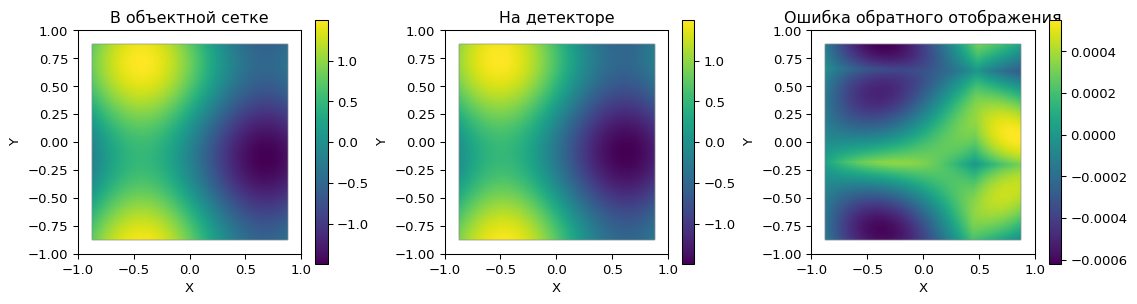

Среднее чисел / аргумент среднего фазора: 0.0 180.0


In [4]:
n=96; yy,xx=np.indices((n,n))
true_field=np.sin(xx/17)+.5*np.cos(yy/13)
H=np.array([[1.,.025,2.],[-.015,1.,-1.],[0,0,1.]])
object_coords=H@np.vstack([xx.ravel(),yy.ravel(),np.ones(n*n)])
detector=(np.sin(object_coords[0]/17)+.5*np.cos(object_coords[1]/13)).reshape(n,n)
source=np.linalg.inv(H)@np.vstack([xx.ravel(),yy.ravel(),np.ones(n*n)])
corrected=ndimage.map_coordinates(detector,[source[1],source[0]],order=1,mode='constant',cval=np.nan).reshape(n,n)
roi=np.ones((n,n),bool); roi[:6]=False; roi[-6:]=False; roi[:,:6]=False; roi[:,-6:]=False
print('RMS до / после:',np.sqrt(np.mean((detector-true_field)[roi]**2)),np.sqrt(np.mean((corrected-true_field)[roi]**2)))
cl.show_maps([true_field,detector,corrected-true_field],['В объектной сетке','На детекторе','Ошибка обратного отображения'],roi)
angles=np.deg2rad([179,-179])
print('Среднее чисел / аргумент среднего фазора:',np.rad2deg(angles.mean()),np.rad2deg(np.angle(np.exp(1j*angles).mean())))

## 4. Вычитание калибровочной карты

Измеряем $W_{raw}=W_{sample}+W_{instrument}+\epsilon$ и вычитаем оценку инструментальной
ошибки. Обе карты должны описывать одну величину, в одних единицах и согласованных
координатах, при совместимой конфигурации. Карта эталона, OPD и высота поверхности
не становятся взаимозаменяемыми только потому, что имеют одинаковый размер массива.

Независимая калибровочная погрешность добавляет дисперсию:
$\sigma_{corr}^2=\sigma_{raw}^2+\sigma_{cal}^2$.
При корреляции нужен член $-2\operatorname{Cov}(raw,cal)$.
Ошибка регистрации Δx даёт приблизительно $\delta W\approx\nabla W\cdot\Delta x$.
Даже очень точная калибровочная карта может навредить при неправильном совмещении.

RMS ошибки при смещении калибровки на 1 px: 0.006222317571911813


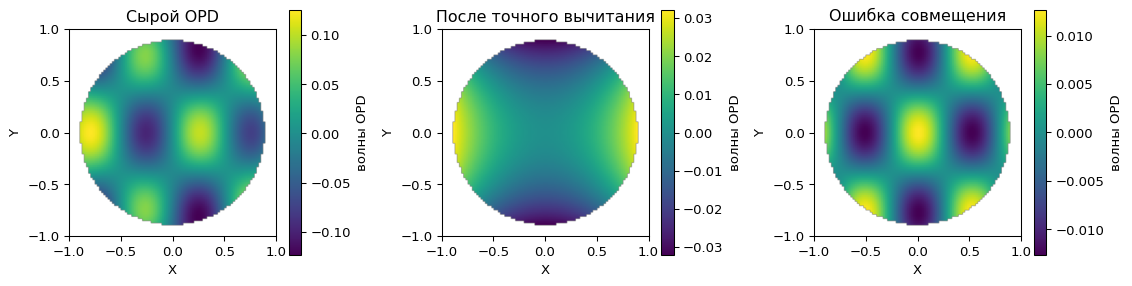

In [5]:
x,y=cl.grid(96); mask=x*x+y*y<.9**2
sample=.04*(x*x-y*y)
instrument=.1*np.sin(6*x)*np.cos(4*y)
raw=sample+instrument
wrong_calibration=ndimage.shift(instrument,(0,1),order=1,mode='nearest')
correct=raw-instrument; wrong=raw-wrong_calibration
print('RMS ошибки при смещении калибровки на 1 px:',cl.compare(wrong,sample,mask)[1]['rms'])
cl.show_maps([raw,correct,wrong-sample],['Сырой OPD','После точного вычитания','Ошибка совмещения'],mask,units='волны OPD')

## 5. RMS, PV и число Штреля

PV=max−min чувствителен к одиночным выбросам. RMS относительно среднего описывает
распределение отклонений, но не их пространственное расположение.
Для зрачка $P=Ae^{i2\pi W/\lambda}$ PSF пропорциональна $|\mathcal F(P)|^2$.
Сравнивать надо с идеальной PSF при том же зрачке и энергии.

Для малых фазовых ошибок приближение Марешаля:
$S\approx\exp[-(2\pi\sigma_W/\lambda)^2]$.
Нужен RMS **OPD**, не высоты поверхности. Для отражения при нормальном падении
σW=2σh. Удалённый в программе дефокус не означает, что дефокус реально исправлен
в оптической системе; Штрель остатка характеризует именно принятую коррекцию.

Штрель FFT / Марешаль: 0.9527385317041847 0.9529617724603301
1000 nm, σW=50 nm: 0.906018055788923
1000 nm, σh=50 nm в отражении: 0.6738254512314336


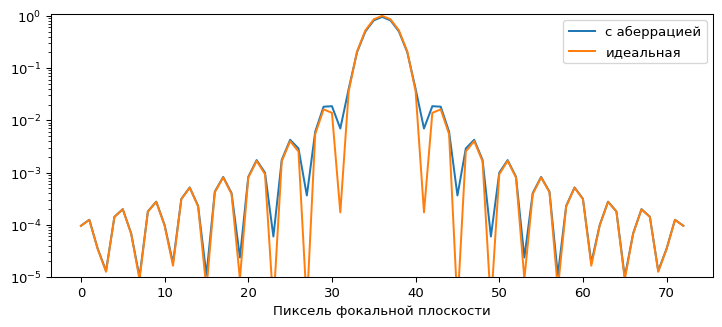

In [6]:
x,y=cl.grid(128); pupil=x*x+y*y<=1
opd_waves=.035*cl.zernike(2,0,x,y,'rms')
ideal=np.abs(np.fft.fftshift(np.fft.fft2(pupil.astype(float),s=(512,512))))**2
aberrated=np.abs(np.fft.fftshift(np.fft.fft2(pupil*np.exp(2j*np.pi*opd_waves),s=(512,512))))**2
sigma=np.std(opd_waves[pupil])
strehl_fft=aberrated.max()/ideal.max()
strehl_approx=np.exp(-(2*np.pi*sigma)**2)
print('Штрель FFT / Марешаль:',strehl_fft,strehl_approx)
print('1000 nm, σW=50 nm:',np.exp(-(2*np.pi*50/1000)**2))
print('1000 nm, σh=50 nm в отражении:',np.exp(-(2*np.pi*100/1000)**2))
plt.plot(aberrated[256,220:293]/ideal.max(),label='с аберрацией')
plt.plot(ideal[256,220:293]/ideal.max(),label='идеальная')
plt.yscale('log'); plt.ylim(1e-5,1.1); plt.xlabel('Пиксель фокальной плоскости'); plt.legend(); plt.show()

## 6. Бюджет погрешностей и спектр поверхности

Для $h=\lambda\varphi/(4\pi)$ при независимых малых ошибках:
$$\sigma_h^2\approx(\lambda/4\pi)^2\sigma_\varphi^2
+(\varphi/4\pi)^2\sigma_\lambda^2.$$
Добавляются калибровка, регистрация, нестабильность, нелинейность камеры и ошибка
модели. Нельзя включать неизвестные систематические ошибки как независимый белый шум.

Две поверхности могут иметь одинаковый RMS и разные пространственные частоты.
Для одномерного профиля с шагом dx и длиной L=Ndx двусторонняя PSD
$S_k=(dx/N)|FFT(z)_k|^2$; $\sum_k S_k\Delta f=\langle z^2\rangle$.
У PSD единицы «высота² × длина». Окно и удаление тренда меняют оценку; для 2D
нужны соответствующие размерности и учёт маски. Порог требований зависит от назначения детали.

Дисперсия в координатах / по PSD: 0.050121204309073575 0.05012120430907357


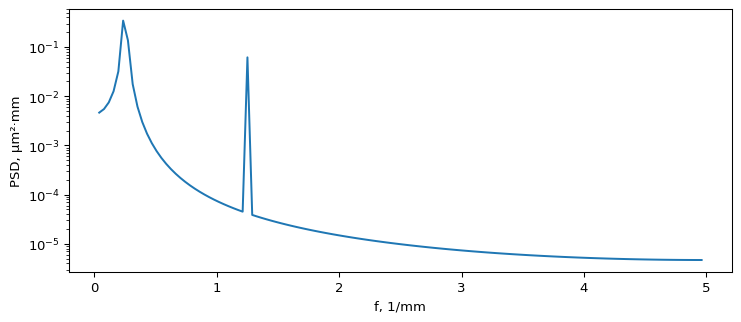

In [7]:
N=256; dx=.1
coordinate=np.arange(N)*dx
profile=.3*np.sin(2*np.pi*coordinate/4)+.1*np.sin(2*np.pi*coordinate/.8)
profile-=profile.mean()
psd=dx/N*np.abs(np.fft.fft(profile))**2
df=1/(N*dx)
print('Дисперсия в координатах / по PSD:',np.mean(profile**2),psd.sum()*df)
assert np.isclose(np.mean(profile**2),psd.sum()*df)
positive=np.fft.fftfreq(N,dx)>0
plt.semilogy(np.fft.fftfreq(N,dx)[positive],psd[positive]); plt.xlabel('f, 1/mm'); plt.ylabel('PSD, μm²·mm')
plt.show()

## Задания

1. Задайте одинаковый RMS, но разные частоты профиля; сравните PSD.
2. Посчитайте ошибку высоты от σφ=0.01 rad при λ=10.6 μm и нормальном отражении.
3. Что нужно хранить вместе с калибровочной картой, кроме массива значений?
4. Почему нельзя сравнивать Штрель остатка с измеренной PSF без описания удалённых мод?

<details><summary>Разбор</summary>

PSD перемещает энергию по частотам при том же интеграле. σh≈8.44 nm.
Нужны величина, единицы, λ, конфигурация, координаты, сетка, маска, дата/условия
получения и оценка неопределённости. Удалённые виртуально аберрации могут
присутствовать в реально измеренной PSF.
</details>

**В проекте:** `FiducialTransformFit`, S4, `ModalAnalysisReportData` и концепции
в `notes/architecture.md`. Наличие подгонки реперов не означает, что преобразование
уже применяется ко всем данным конвейера.
Далее: [итоговая лабораторная](12_validation_lab.ipynb).